# Más allá: la definición de incumplimiento es parte de la PD, los retiros informativos y las cohortes delgadas

**Pregunta:** ¿Puede un banco tomar al pie de la letra una PD de las tablas de una agencia calificadora: cuánto mueven el número la definición de incumplimiento, el tratamiento de las calificaciones retiradas y lo delgado de un grado, y cuánto más que el error de muestreo que informa el intervalo habitual?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los notebooks 01, 02 y 07 de este tema (la PD por grado, los intervalos y la función IRB)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook puedes:

- mostrar con los datos de una agencia que la definición de incumplimiento es parte de la PD: el mismo grado tiene dos PD de largo plazo que difieren en un factor de tres bajo dos páginas de la misma publicación, y el ponderador de riesgo de la cartera se mueve con ella;
- decir cómo se compara el error de muestreo de una PD con el efecto de la definición;
- medir sobre trayectorias de calificación de verdad conocida cuánto sesgan una PD los retiros informativos bajo los tres tratamientos en uso, y por qué ninguna prueba de la matriz lo ve;
- medir exactamente con qué frecuencia el intervalo de un grado delgado contiene su PD con tres métodos de intervalo;
- enunciar la afirmación BS-4 del producto, la evidencia que la respalda y sus límites.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.harness.performance import estimator_performance
from riskvalidation.regulatory import irb
from riskvalidation.transitions import estimators, intervals

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres archivos versionados del caso C04 (CEREP de ESMA, clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: las cohortes de S&P con sus conteos y retiros, las PD de largo plazo por grado bajo las páginas de CEREP (`outputs.lra`), su brecha (`outputs.definition_gap`) y los supuestos IRB del caso.
- `data/derived/C04/withdrawals.json`: un estudio de simulación sobre trayectorias de calificación de verdad conocida (el generador del notebook 03) en que una parte de las calificaciones se retira a 6% al año, y más a menudo justo antes del incumplimiento por un factor $1 + k$ con $k$ en 0, 1, 3, 9 (retiros informativos); 200 conjuntos de datos con semilla por peldaño. Este notebook vuelve a correr ese diseño con el motor, y lee del archivo solo las tasas de rechazo de las dos pruebas de la matriz, que necesitan las simulaciones largas del arnés.
- `data/derived/C04/thin.json`: las PD verdaderas del generador y los tamaños del estudio de grados delgados; la cobertura misma se calcula aquí, exactamente, con el motor.

**Las tres páginas.** CEREP declara que "no se ha establecido una definición determinista de un evento de incumplimiento", de modo que toda PD nombra su página. `d2` es la página de incumplimiento: las calificaciones distintas contadas como incumplimientos sobre la cohorte de la propia página. `d3` son sus eventos de incumplimiento sobre la cohorte de la página de transición. `d4` es la columna de incumplimiento de la página de transición sobre la cohorte menos sus retiros, el tratamiento de la industria.

In [2]:
# Load the three committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))
wd = json.loads((C04 / "withdrawals.json").read_text(encoding="utf-8"))
thin = json.loads((C04 / "thin.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades = out["grades"]

## Método

### Paso 1: la definición es parte de la PD

La tasa media de incumplimiento de largo plazo (EBA/GL/2017/16, párrafo 84) es el promedio de las tasas anuales sobre las cohortes en que el grado tiene calificaciones, como en el notebook 01. La celda siguiente la lee para cada grado bajo la página de incumplimiento (`d2`), los eventos de incumplimiento sobre la cohorte de transición (`d3`) y la página de transición (`d4`). Luego pregunta cuán grande es la incertidumbre de muestreo del número `d4`, con dos varas de medir: el intervalo de Jeffreys del motor sobre los conteos agrupados del grado CCC a C, y el error estándar del promedio de sus 26 tasas anuales, una vara más justa para un promedio de largo plazo porque las tasas anuales se mueven juntas con el ciclo de crédito (Schuermann y Hanson, 2004, corrigen esta correlación con un efecto de diseño). Por último mide la brecha entre las dos páginas frente a ambas.

In [3]:
# Long-run PD under the three pages, and the sampling uncertainty of the CCC to C rate of the transition page
lra = {d: np.array(out["lra"][d]["rate"], dtype=float) for d in ("d2", "d3", "d4")}
counts, at_risk = np.array(out["lra"]["d4"]["defaults"]), np.array(out["lra"]["d4"]["n"])
jeffreys = intervals.pd_jeffreys(counts, at_risk)
half = float(jeffreys["upper"][6] - jeffreys["lower"][6]) / 2
yearly = np.array([c["counts"][6][7] / (c["size"][6] - c["withdrawn"][6]) for c in out["cohorts"]])
cycle_se = yearly.std(ddof=1) / np.sqrt(len(yearly))
gap = lra["d2"][6] - lra["d4"][6]

print(f"CCC to C: d2 {lra['d2'][6]:.4f}, d3 {lra['d3'][6]:.4f}, d4 {lra['d4'][6]:.4f}")
print(f"intervalo de Jeffreys de d4, conteos agrupados: {jeffreys['lower'][6]:.4f} to {jeffreys['upper'][6]:.4f}")
print(f"brecha d2 menos d4 {gap:.4f} = {gap / half:.1f} semiamplitudes de ese intervalo")
print(f"brecha en errores estándar del promedio anual {gap / cycle_se:.1f} ({cycle_se:.4f})")
ratio = lra["d4"][1:] / lra["d2"][1:]
print(f"d4 / d2 por grado, AA a CCC a C: {np.round(ratio, 3)}")

CCC to C: d2 0.2664, d3 0.2758, d4 0.0861
intervalo de Jeffreys de d4, conteos agrupados: 0.0723 to 0.0897
brecha d2 menos d4 0.1803 = 20.6 semiamplitudes de ese intervalo
brecha en errores estándar del promedio anual 14.9 (0.0121)
d4 / d2 por grado, AA a CCC a C: [0.52  0.871 0.699 0.635 0.45  0.323]


Sigue lo que la definición hace al capital. La celda siguiente toma la mezcla de grados de las 26 cohortes y las PD de largo plazo bajo `d2` y `d4`, y calcula el ponderador de riesgo corporativo medio de Basilea III con la función IRB del motor (vencimiento 2,5, piso de PD 0,05%; la función es CRE31.5, los parámetros CRE32, https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27), como en el notebook 07. La LGD de 45% es el valor IRB básico para créditos preferentes sin garantía contra instituciones financieras (CRE32.6), combinada con la correlación de los corporativos no financieros y sin el multiplicador de 1,25 de CRE31.7: el supuesto del caso, que fija el nivel de los ponderadores y no la comparación, pues el ponderador es proporcional a la LGD.

In [4]:
# Average IRB risk weight of the cohort mix under d2 and d4
spec = out["irb"]
settings = {"lgd": spec["lgd"], "maturity": spec["maturity"], "regime": spec["regime"]}
mix = np.array([c["size"] for c in out["cohorts"]], dtype=float).sum(axis=0)
mix = mix / mix.sum()
portfolio = {}
for definition in ("d2", "d4"):
    results = [irb.capital_requirement(spec["asset_class"], float(p), **settings) for p in lra[definition]]
    portfolio[definition] = float(mix @ np.array([r.risk_weight for r in results]))
    print(f"{definition}: ponderador de riesgo medio {portfolio[definition]:.4f}")
print(f"cambio de d2 a d4 {portfolio['d4'] / portfolio['d2'] - 1:.3f}")

d2: ponderador de riesgo medio 0.5797
d4: ponderador de riesgo medio 0.4745
cambio de d2 a d4 -0.181


La figura dibuja a la izquierda la PD de largo plazo de cada grado bajo las tres páginas, y a la derecha el ponderador de riesgo de la cartera bajo las dos definiciones de la PD.

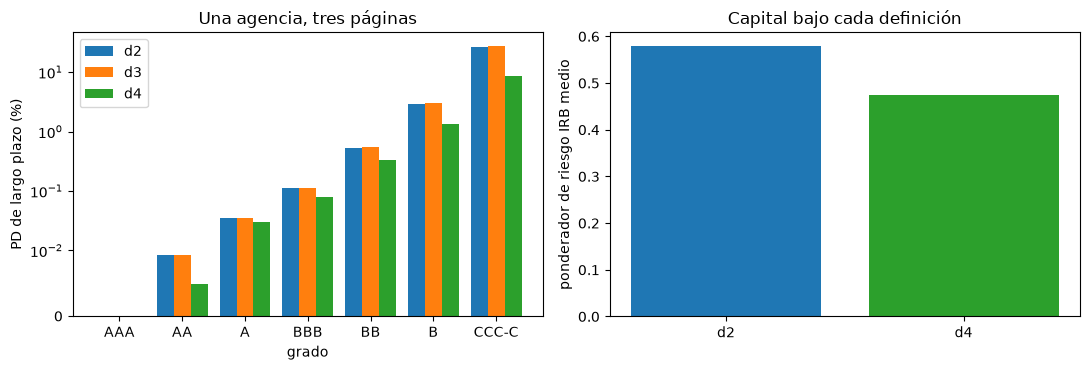

In [5]:
# Draw the long-run PD by page and the portfolio risk weight by definition
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
width = 0.27
for k, d in enumerate(("d2", "d3", "d4")):
    left.bar(np.arange(7) + (k - 1) * width, 100 * lra[d], width, label=d)
left.set_yscale("symlog", linthresh=0.01)
left.set_xticks(range(7))
left.set_xticklabels(grades)
left.set_xlabel("grado")
left.set_ylabel("PD de largo plazo (%)")
left.set_title("Una agencia, tres páginas")
left.legend()
right.bar(["d2", "d4"], [portfolio["d2"], portfolio["d4"]], color=["tab:blue", "tab:green"])
right.set_ylabel("ponderador de riesgo IRB medio")
right.set_title("Capital bajo cada definición")
fig.tight_layout()
plt.show()

El panel izquierdo muestra la definición en acción en todos los grados desde AA hacia abajo: las barras de `d4` son más cortas que las de `d2`, en cerca de una décima en A, un tercio en BBB y un factor de tres en CCC a C, mientras que `d3`, los mismos incumplimientos sobre la cohorte de transición, queda a pocos por ciento de `d2`. Así que la cohorte y el tratamiento de los retiros, y no el conteo de incumplimientos, hacen la diferencia. La brecha impresa, 18,0 puntos para CCC a C, equivale a 20,6 semiamplitudes del intervalo de Jeffreys y a 14,9 errores estándar del promedio anual: el muestreo, aun considerando el ciclo, no se le acerca. A la derecha la definición mueve el ponderador de riesgo medio de la cartera en 18%. La figura no dice cuál página es la correcta, solo que la PD no puede leerse sin nombrarla.

### Paso 2: retiros informativos

Una calificación se retira cuando la agencia deja de calificar al deudor. El tratamiento de la industria (la página de transición de CEREP) trata un retiro como no informativo: lo quita y divide por lo que queda (Schuermann y Hanson, 2004, nota 4). EBA/GL/2017/16, párrafo 76, pide en cambio mantener las obligaciones cerradas y seguirlas. Si los deudores en problemas se retiran más a menudo, ambos tratamientos quedan sesgados, y un validador no puede verlo en la matriz. El diseño es el del estudio versionado. Las trayectorias de calificación salen del generador del notebook 03 durante cinco años de fotos anuales, 6% de las calificaciones se retira cada año, y una calificación se retira $1 + k$ veces más a menudo en el año previo a su incumplimiento, con $k$ = 0 (no informativo), 1, 3 y 9. La misma secuencia aleatoria genera las trayectorias latentes y las observadas, de modo que cada conjunto de datos es pareado. Para cada peldaño la celda siguiente calcula la PD a un año de cuatro maneras: con los retiros **quitados**, **mantenidos** sin seguir como estado absorbente, **seguidos** (la cohorte de cada año tal como se observa, con su final leído en la trayectoria latente, de modo que una calificación retirada dentro del año que incumple al final cuenta como incumplimiento), y desde la cadena **latente** (cada deudor seguido cada año), que es la referencia que ve a todos. Usa 200 conjuntos de datos por peldaño y toma unos segundos.

In [6]:
# Draw paired latent and observed paths along the ladder and estimate the PD with four treatments of withdrawals
q_true = np.array(thin["outputs"]["generator"]["q"], dtype=float)
obligors = tuple(thin["outputs"]["generator"]["obligors"])
snapshots = tuple(float(t) for t in range(6))
latent_gen = RatingPaths(q_true, obligors, horizon=5.0, snapshots=snapshots)
truth = np.array(latent_gen.truth()["pd_by_grade"]["1"])
treatments = ("removed", "kept", "followed", "latent")
shown = {"removed": "quitados", "kept": "mantenidos", "followed": "seguidos"}
shown |= {"latent": "latente", "wald": "Wald", "agresti_coull": "Agresti-Coull", "jeffreys": "Jeffreys"}
ladder = (0, 1, 3, 9)
estimates = {}
for k in ladder:
    spec_k = {"withdrawal_rate": 0.06, "informative": k, "window": 1.0}
    gen = RatingPaths(q_true, obligors, horizon=5.0, snapshots=snapshots, **spec_k)
    estimates[k] = {name: np.zeros((200, 7)) for name in treatments}
    for i, child in enumerate(np.random.SeedSequence(7).spawn(200)):
        latent = latent_gen.draw(np.random.default_rng(child))
        seen = gen.draw(np.random.default_rng(child))
        tables, gone = [s["counts"] for s in seen["steps"]], [s["withdrawn"] for s in seen["steps"]]
        estimates[k]["removed"][i] = estimators.pooled_cohort(tables, gone)["matrix"][:7, 7]
        estimates[k]["kept"][i] = estimators.pooled_cohort(tables, gone, treatment="state")["matrix"][:7, 7]
        first, last = seen["snapshot_states"], latent["snapshot_states"]
        years = [gen.snapshot_counts(np.column_stack([first[:, t], last[:, t + 1]]))[0] for t in range(5)]
        estimates[k]["followed"][i] = estimators.pooled_cohort([s["counts"] for s in years])["matrix"][:7, 7]
        every = [s["counts"] for s in latent["steps"]]
        estimates[k]["latent"][i] = estimators.pooled_cohort(every)["matrix"][:7, 7]
print("PD verdadera a un año de B y CCC a C:", np.round(truth[5:], 4))
print("conjuntos de datos por peldaño:", estimates[0]["removed"].shape[0], "| peldaños k:", ladder)

PD verdadera a un año de B y CCC a C: [0.0117 0.0806]
conjuntos de datos por peldaño: 200 | peldaños k: (0, 1, 3, 9)


La celda siguiente resume cada tratamiento con `estimator_performance` del motor: el sesgo relativo a la PD verdadera y su error estándar de Monte Carlo, para B y para CCC a C en cada peldaño.

In [7]:
# Relative bias of each treatment and its Monte Carlo error, from the engine's performance harness
bias, bias_se = {}, {}
for k in ladder:
    rows = {n: [estimator_performance(estimates[k][n][:, g], truth[g]) for g in (5, 6)] for n in treatments}
    bias[k] = {n: np.array([r["bias"] / truth[g] for r, g in zip(rows[n], (5, 6))]) for n in treatments}
    bias_se[k] = {n: np.array([r["bias_mcse"] / truth[g] for r, g in zip(rows[n], (5, 6))]) for n in treatments}
print(f"{'k':>4s}" + "".join(f"{shown[n]:>22s}" for n in treatments) + "   (B)")
for k in ladder:
    print(f"{k:4d}" + "".join(f"{bias[k][n][0]:+13.3f} ({bias_se[k][n][0]:.3f})" for n in treatments))
print(f"k = 9, CCC a C: " + ", ".join(f"{shown[n]} {bias[9][n][1]:+.3f}" for n in treatments))

   k              quitados            mantenidos              seguidos               latente   (B)
   0       +0.022 (0.009)       -0.037 (0.009)       -0.004 (0.009)       -0.004 (0.008)
   1       -0.028 (0.009)       -0.085 (0.008)       -0.023 (0.009)       -0.004 (0.008)
   3       -0.127 (0.008)       -0.180 (0.008)       -0.061 (0.008)       -0.004 (0.008)
   9       -0.360 (0.008)       -0.400 (0.007)       -0.162 (0.008)       -0.004 (0.008)
k = 9, CCC a C: quitados -0.338, mantenidos -0.392, seguidos -0.185, latente +0.003


La figura dibuja el sesgo relativo de la PD de B con cada tratamiento a lo largo del peldaño, con su error de Monte Carlo como barra, para los cuatro valores de $k$.

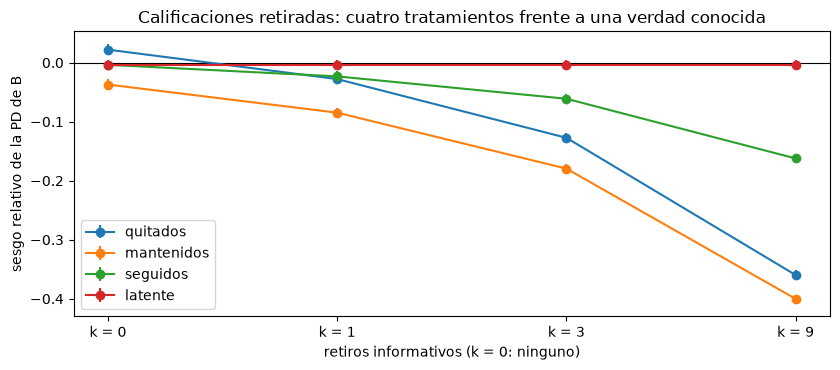

In [8]:
# Draw the relative bias of the PD of B under each treatment along the ladder
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for n in treatments:
    centre = [bias[k][n][0] for k in ladder]
    ax.errorbar(range(len(ladder)), centre, [bias_se[k][n][0] for k in ladder], marker="o", label=shown[n])
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set_xticks(range(len(ladder)))
ax.set_xticklabels([f"k = {k}" for k in ladder])
ax.set_xlabel("retiros informativos (k = 0: ninguno)")
ax.set_ylabel("sesgo relativo de la PD de B")
ax.set_title("Calificaciones retiradas: cuatro tratamientos frente a una verdad conocida")
ax.legend()
fig.tight_layout()
plt.show()

La cadena latente, que ve a todos, se queda en cero en todos los peldaños, de modo que el generador y el estimador son sólidos. Los tres tratamientos de las trayectorias observadas se alejan de ella a medida que crece $k$. Con $k = 0$ los tratamientos de quitar y de mantener ya tienen un sesgo pequeño, hacia arriba al quitar y hacia abajo al mantener, porque mantener trata un retiro como un estado absorbente que no puede incumplir. Con $k = 9$, el peldaño más fuerte, quitar las calificaciones retiradas subestima la PD de B en 36%, mantenerlas en 40%, y seguirlas como pide el párrafo 76 todavía la subestima en 16%. Seguir es el menos sesgado de los tres, y no es insesgado. Las barras son pequeñas junto a estas brechas, de modo que la deriva con $k$ no es ruido de Monte Carlo, pero la figura no dice nada sobre si los retiros de CEREP son informativos: aquí están plantados.

La pregunta siguiente es si las pruebas que un validador tiene sobre la matriz lo notarían. Las dos pruebas de matriz del estudio, la homogeneidad temporal entre las cinco matrices anuales y los conteos del último año contra la matriz exacta, son simulaciones de Monte Carlo de 200 conjuntos de datos cada una en el arnés, de modo que sus tasas de rechazo al 5% se leen del archivo versionado para cada peldaño. Una prueba sin poder rechaza cerca de 5% de los conjuntos o menos, sea cual sea el sesgo.

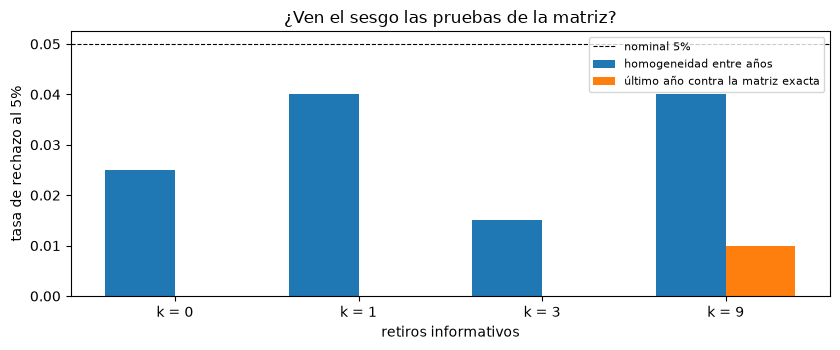

conjuntos de datos por fila: 200


In [9]:
# Draw the committed rejection rates at 5% of the two matrix tests along the ladder
sims = wd["outputs"]["simulations"]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
width = 0.38
tests_shown = (("rating.time_homogeneity", "homogeneidad entre años"),
               ("rating.matrix_reference", "último año contra la matriz exacta"))
for j, (test_id, label) in enumerate(tests_shown):
    rows = [next(s for s in sims if s["test_id"] == test_id and s["rung"] == k) for k in ladder]
    rates = [row["rates"]["p<0.05"]["rate"] for row in rows]
    ax.bar(np.arange(len(ladder)) + (j - 0.5) * width, rates, width, label=label)
ax.axhline(0.05, color="black", linestyle="--", linewidth=0.8, label="nominal 5%")
ax.set_xticks(range(len(ladder)))
ax.set_xticklabels([f"k = {k}" for k in ladder])
ax.set_xlabel("retiros informativos")
ax.set_ylabel("tasa de rechazo al 5%")
ax.set_title("¿Ven el sesgo las pruebas de la matriz?")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("conjuntos de datos por fila:", sims[0]["n_rep"])

Ambas pruebas rechazan en o bajo su 5% nominal en todos los peldaños, incluido $k = 9$, donde el sesgo es un tercio de la PD: la matriz de las calificaciones que siguen ahí pasa como matriz de Markov, y la información que falta es justo lo que ninguna prueba sobre ella puede ver. La prueba de homogeneidad rechaza unos pocos por ciento sea cual sea $k$, y la del último año casi nunca rechaza. La figura dice que estas dos pruebas no pueden ser la salvaguarda frente a los retiros informativos; no dice que ninguna prueba pueda serlo, pues una prueba que comparara las calificaciones retiradas con las sobrevivientes necesitaría datos que la página de transición no publica.

### Paso 3: grados delgados

El notebook 02 mostró que el intervalo de Wald de un grado sin incumplimientos observados tiene ancho cero. ¿Con qué frecuencia contiene cada intervalo la PD verdadera cuando el grado es delgado? La cobertura de un método de intervalo para $n$ deudores con PD verdadera $p$ es exacta: se suma la probabilidad binomial de cada conteo de incumplimientos cuyo intervalo contiene a $p$. El `exact_coverage` del motor lo hace. La celda siguiente la calcula para los intervalos de Wald, Agresti-Coull y Jeffreys en las PD verdaderas a un año del generador y los tamaños de 50 a 1.000 deudores por grado que usa el estudio, e imprime la cobertura de los tres mejores grados en el menor y el mayor tamaño.

In [10]:
# Exact coverage of three intervals at the true PDs of the generator, by number of obligors per grade
sizes = [r["value"] for r in thin["outputs"]["rungs"]]
true_pd = np.array(thin["outputs"]["generator"]["pd_1y"])
coverage = {}
for method in ("wald", "agresti_coull", "jeffreys"):
    coverage[method] = np.array([intervals.exact_coverage(method, n, true_pd, level=0.95)["coverage"] for n in sizes])
print("PD verdadera a un año de AAA, AA y A:", np.round(true_pd[:3], 5))
for method in coverage:
    for at in (0, -1):
        c = coverage[method][at]
        print(f"{shown[method]:14s} n = {sizes[at]:5d}: AAA {c[0]:.4f}, AA {c[1]:.4f}, A {c[2]:.4f}")
print("nivel nominal: 0.95")

PD verdadera a un año de AAA, AA y A: [7.0e-05 5.0e-05 2.9e-04]
Wald           n =    50: AAA 0.0033, AA 0.0025, A 0.0143
Wald           n =  1000: AAA 0.0636, AA 0.0479, A 0.2506
Agresti-Coull  n =    50: AAA 1.0000, AA 1.0000, A 0.9999
Agresti-Coull  n =  1000: AAA 1.0000, AA 1.0000, A 0.9968
Jeffreys       n =    50: AAA 0.9967, AA 0.9975, A 0.9857
Jeffreys       n =  1000: AAA 0.9364, AA 0.9521, A 0.9656
nivel nominal: 0.95


La figura dibuja la cobertura exacta de los tres intervalos para AAA y para A frente al número de deudores, con el nivel nominal como línea punteada.

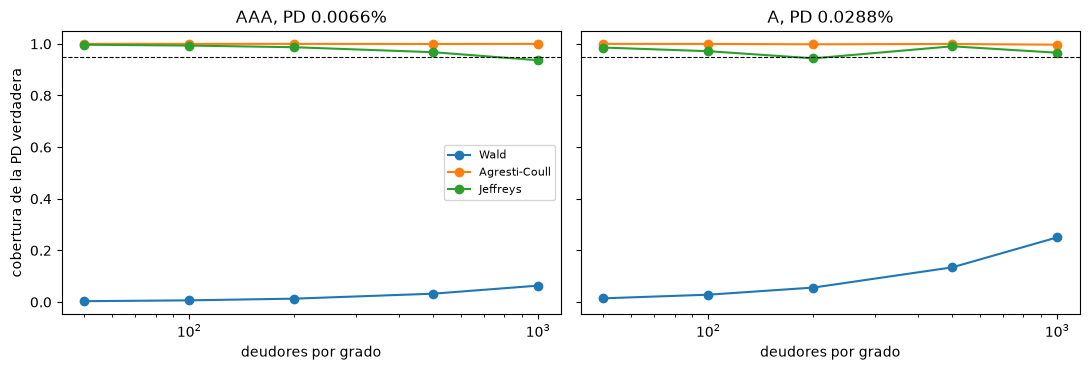

In [11]:
# Draw the exact coverage of the three intervals for AAA and A against the sample size
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, g in zip(axes, (0, 2)):
    for method in coverage:
        ax.plot(sizes, coverage[method][:, g], marker="o", label=shown[method])
    ax.axhline(0.95, color="black", linestyle="--", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("deudores por grado")
    ax.set_title(f"{grades[g]}, PD {100 * true_pd[g]:.4f}%")
axes[0].set_ylabel("cobertura de la PD verdadera")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

El intervalo de Wald queda muy bajo la línea punteada para AAA en todos los tamaños: con 50 deudores contiene la PD verdadera en 0,33% de las muestras, porque la contiene solo cuando ocurre un incumplimiento, y la probabilidad de uno es la PD por 50. Más deudores ayudan lentamente: para AAA sigue cerca de 6% con 1.000, y para A, cuya PD es cuatro veces mayor, sube de 1,4% a cerca de un cuarto. El intervalo de Agresti-Coull sobrecubre cerca de 100% porque ensancha el intervalo alrededor de una tasa de cero. El intervalo de Jeffreys es el que más se acerca al nivel nominal: para AAA cubre 99,7% con 50 deudores y 93,6% con 1.000. La figura es exacta para las PD y tamaños de este generador; es una escala de calificación con estas PD por grado, no cualquier cartera.

## Estado del arte

### La práctica que esto supera

- **La definición.** La publicación CEREP de ESMA declara que no se ha establecido para ella una definición determinista de un evento de incumplimiento, y los estimadores de cohortes y de duración de la literatura toman las tablas de las agencias como dadas (Schuermann y Hanson, 2004; el dossier de investigación 13, secciones 4 y 5). Una PD de una tabla de CEREP se lee entonces como un número, con su error de muestreo, y la definición detrás de ella no es parte de la estimación.
- **Retiros.** La industria los quita (Schuermann y Hanson, nota 4), el párrafo 76 de la EBA pide mantenerlos y seguirlos; la práctica discute la elección y no mide el sesgo de cada una frente a una verdad.
- **Grados delgados.** Schuermann y Hanson usan los intervalos de Wald y de Agresti-Coull para las PD por grado, con una corrección de efecto de diseño por correlación; Brown, Cai y DasGupta (2001) estudian su cobertura para una proporción binomial en general. La cobertura de cada uno en las PD y tamaños de una escala de calificación es la pregunta que la práctica deja.

El notebook mide cada una de las tres sobre la misma agencia y sobre un generador de verdad conocida.

## Más allá del estado del arte

### Afirmación BS-4: la definición de incumplimiento como parte de la PD, los retiros informativos y los grados delgados

**Lo que Contraste agrega.** La PD de largo plazo del grado CCC a C de la misma agencia es 26,6% bajo la página de incumplimiento de CEREP y 8,6% bajo la página de transición, y el ponderador de riesgo IRB de la mezcla de cohortes se mueve con la definición en una quinta parte; los retiros informativos y los grados delgados se miden sobre trayectorias de calificación de verdad conocida, con el motor, y la cobertura de los intervalos habituales se calcula exactamente. La celda siguiente lista cada afirmación con el valor que este notebook calculó arriba, de modo que la afirmación puede revisarse enunciado por enunciado.

In [12]:
# Each statement of the claim with the value this notebook computed
statements = [
    ("PD de largo plazo CCC a C, página de incumplimiento (d2), %", 100 * lra["d2"][6]),
    ("PD de largo plazo CCC a C, página de transición (d4), %", 100 * lra["d4"][6]),
    ("ponderador IRB de la mezcla de cohortes con d2, %", 100 * portfolio["d2"]),
    ("ponderador IRB de la mezcla de cohortes con d4, %", 100 * portfolio["d4"]),
    ("B: sesgo relativo, retiros quitados, k = 9, %", 100 * bias[9]["removed"][0]),
    ("B: sesgo relativo, retiros seguidos, k = 9, %", 100 * bias[9]["followed"][0]),
    ("AAA, 50 deudores: cobertura del intervalo de Wald, %", 100 * coverage["wald"][0][0]),
    ("AAA, 50 deudores: cobertura del intervalo de Jeffreys, %", 100 * coverage["jeffreys"][0][0]),
]
for text, value in statements:
    print(f"{value:9.3f}  {text}")

   26.637  PD de largo plazo CCC a C, página de incumplimiento (d2), %
    8.608  PD de largo plazo CCC a C, página de transición (d4), %
   57.969  ponderador IRB de la mezcla de cohortes con d2, %
   47.454  ponderador IRB de la mezcla de cohortes con d4, %
  -35.974  B: sesgo relativo, retiros quitados, k = 9, %
  -16.226  B: sesgo relativo, retiros seguidos, k = 9, %
    0.328  AAA, 50 deudores: cobertura del intervalo de Wald, %
   99.672  AAA, 50 deudores: cobertura del intervalo de Jeffreys, %


**Límites de la afirmación.** La brecha de definición es la de una agencia (S&P, entidad UE, corporativos de largo plazo) y compara dos páginas de una publicación que además cuentan cohortes distintas (el artefacto registra la diferencia de cohortes como un hallazgo); dice que la definición importa, no cuál página es la correcta. Los retiros informativos están plantados en una simulación: el estudio muestra lo que harían y que ninguna prueba de la matriz lo ve, no que los retiros de CEREP sean informativos. La cobertura de grados delgados es exacta para las PD y tamaños del generador, una escala de calificación con estas PD por grado. La afirmación se demuestra con este notebook y los tres archivos de arriba, y no se enuncia más allá de ellos.

La última figura pone lado a lado las tres partes de la afirmación: la PD de CCC a C bajo las dos páginas con el intervalo de `d4`, el sesgo de la PD de B bajo los tres tratamientos con $k = 9$ y la cobertura de los tres intervalos para AAA con 50 deudores.

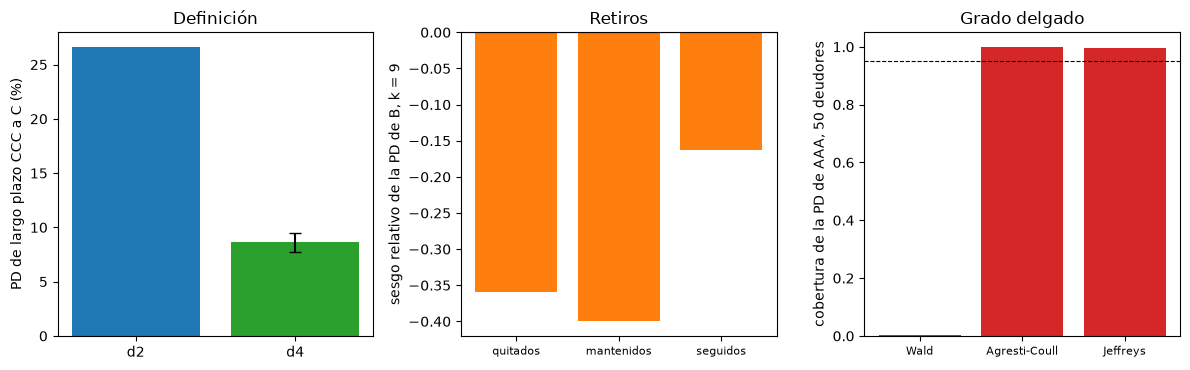

In [13]:
# Draw the three parts of the claim: the definition, the withdrawals and the thin grade
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
pages = ["d2", "d4"]
axes[0].bar(pages, [100 * lra[p][6] for p in pages], color=["tab:blue", "tab:green"])
axes[0].errorbar([1], [100 * lra["d4"][6]], [100 * half], color="black", capsize=4)
axes[0].set_ylabel("PD de largo plazo CCC a C (%)")
axes[0].set_title("Definición")
axes[1].bar([shown[n] for n in treatments[:3]], [bias[9][n][0] for n in treatments[:3]], color="tab:orange")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_ylabel("sesgo relativo de la PD de B, k = 9")
axes[1].set_title("Retiros")
axes[2].bar([shown[m] for m in coverage], [coverage[m][0][0] for m in coverage], color="tab:red")
axes[2].axhline(0.95, color="black", linestyle="--", linewidth=0.8)
axes[2].set_ylabel("cobertura de la PD de AAA, 50 deudores")
axes[2].set_title("Grado delgado")
for ax in axes[1:]:
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
plt.show()

Cada panel es un enunciado de la afirmación en su tamaño principal. A la izquierda, la definición mueve la PD de CCC a C en dos tercios, muy fuera del pequeño intervalo negro en que confiaría un lector de una sola página. En el centro, incluso el mejor tratamiento de los retiros subestima la PD de B en el peldaño más fuerte. A la derecha, el intervalo de Wald casi nunca contiene la PD de AAA con 50 deudores, el de Agresti-Coull casi siempre la contiene, y solo el de Jeffreys está cerca del nivel nominal punteado. Los paneles no se combinan en un solo número: los tres efectos se miden sobre datos distintos y no suman un error total de una PD.

## Resultados

**Respuesta:** No: la PD de largo plazo del grado CCC a C de la misma agencia es 0,2664 bajo la página de incumplimiento y 0,0861 bajo la página de transición, una brecha de 0,1803 que equivale a 20,6 semiamplitudes del intervalo de Jeffreys de la segunda y a 14,9 errores estándar de su promedio anual, y mueve el ponderador de riesgo IRB medio de la mezcla de cohortes de 0,5797 a 0,4745, 0,181 menos. Los retiros informativos con `k = 9` subestiman la PD de B en 0,360 cuando se quitan, 0,400 cuando se mantienen y 0,162 cuando se siguen, y ninguna prueba de la matriz rechaza más que su nivel nominal. En un grado delgado el intervalo de Wald contiene la PD verdadera de AAA en 0,0033 de las muestras con 50 deudores y en 0,0636 con 1.000, frente a 0,9967 y 0,9364 del intervalo de Jeffreys.

- **La definición es parte de la PD.** Bajo la página de incumplimiento la PD de largo plazo de CCC a C es 26,64% y bajo la página de transición 8,61%, una razón de 0,323 (la brecha versionada, agrupada sobre las cohortes donde existen ambas páginas, es 0,294); para B la razón es 0,450. Los eventos de incumplimiento sobre la cohorte de transición (`d3`) quedan a menos de 5% de la página de incumplimiento. El intervalo de Jeffreys de la tasa `d4` sobre los conteos agrupados va de 0,0723 a 0,0897, y el error estándar del promedio de sus 26 tasas anuales es 0,0121: el muestreo, aun con la correlación de las tasas anuales con el ciclo, no se acerca a la definición.
- **Mueve el capital.** El ponderador de riesgo corporativo medio de Basilea III de la mezcla de cohortes es 57,97% con las PD de la página de incumplimiento y 47,45% con las de la página de transición, 18,1% menos.
- **Retiros informativos.** Con `k = 0` quitar y mantener ya se desvían en +0,022 y -0,037 para B, y el sesgo crece con `k`: con `k = 9` los tres tratamientos subestiman la PD de B en 0,360, 0,400 y 0,162 y la de CCC a C en 0,338, 0,392 y 0,185, con un error de Monte Carlo de cerca de 0,008 en B, mientras que la cadena latente queda en -0,004. Las tasas de rechazo al 5% de las dos pruebas de la matriz se mantienen dentro de su nivel nominal en todos los peldaños, de modo que ninguna prueba de la matriz ve el sesgo.
- **Grados delgados.** Con 50 deudores por grado el intervalo de Wald contiene la PD verdadera de AAA en 0,33% de las muestras (AA 0,25%, A 1,43%) y solo en 6,36% con 1.000 deudores (AA 4,79%, A 25,06%); el intervalo de Agresti-Coull la contiene en al menos 99,99% de las muestras para AAA y AA y el de Jeffreys en 99,67% con 50 deudores y 93,64% con 1.000 (nominal 95%).
- **La afirmación.** Los ocho enunciados de la afirmación BS-4 se listan con los valores que este notebook calculó.

Lo que este notebook no muestra: que los retiros de CEREP sean informativos (están plantados en la simulación), ni cuál página de CEREP es la definición correcta (la afirmación es que la elección importa y no está en la estimación).

## Resumen

- La PD de largo plazo del grado CCC a C de la misma agencia es 26,6% o 8,6% según la página de CEREP de la que se lee, y el ponderador de riesgo de la mezcla de cohortes se mueve una quinta parte; la definición es parte de la PD y no está en su intervalo de confianza.
- Los retiros informativos subestiman una PD en un tercio cuando se quitan y en cerca de un sexto cuando se siguen, y ninguna prueba de la matriz lo ve.
- El intervalo de Wald de un grado delgado casi nunca contiene su PD; el de Jeffreys sí, y el de Agresti-Coull sobrecubre.
- La afirmación BS-4 se enuncia solo hasta donde llegan estos archivos versionados y este notebook.

**Qué probar después.** Vuelve a correr el peldaño del Paso 2 para otro grado y mira dónde divergen los tres tratamientos; luego lee el notebook 11 sobre las reconciliaciones.

## Referencias

- ESMA, CEREP publication of credit rating agency ratings and transitions, con su archivo de ayuda ESMA65-8-10634 (secciones 4.2 a 4.4 sobre las páginas y la declaración sobre la definición de incumplimiento). https://registers.esma.europa.eu/cerep-publication/
- Schuermann, T. y Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, nota 4 (retiros) y sección 3 (intervalos). https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- BCBS, Basel Framework, CRE32, enfoque IRB: cálculo de los activos ponderados por riesgo. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- EBA (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, párrafos 73, 76, 84 y 86.